# Latent profiles of personality traits

## 1. Research question

How do two and four Gaussian mixture components summarize the same multidimensional trait scores? Can we distinguish broad elevation from profile shape, and what happens to assignment stability when we add components?

**Data provenance.** All data are completely synthetic. The simulation deliberately uses four underlying components for teaching. Every table and figure comes from fictional scores. The four-profile result reflects the simulation design and provides no empirical evidence about personality profiles.

## 2. Why latent profiles?

Trait scores are continuous. A mixture model represents their joint distribution as a weighted combination of component distributions. A component summarizes a pattern of scores with a mean and within-component variability. Each record has a posterior probability of belonging to each component.

A mixture can summarize an overall trait gradient or reveal relative elevations on specific traits. Whether the components correspond to distinct psychological groups requires additional evidence.

## 3. Synthetic data generation

The generator creates 1,000 observations over 25 generic facets. There are five indicators per illustrative block.

| Prefix | Block |
|---|---|
| DET | Detachment |
| UE | Unusual experiences |
| ANT | Antagonism |
| DIS | Disinhibition |
| NA | Negative affect |

The four underlying components are specified in the generator, with independent Gaussian noise within each component. The two middle components have an opposing contrast between antagonism and negative affect. This is a deliberately favorable benchmark for learning how shape and elevation differ. The indicators are fictional and have no instrument scoring key.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Support kernels started from either the repository root or notebooks/.
root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if not (root / "src" / "simulation.py").is_file():
    raise FileNotFoundError("Start Jupyter from the repository root or notebooks directory.")
sys.path.insert(0, str(root))

from src.simulation import BLOCKS, FACETS, simulate_facets
from src.modeling import compare_models, describe_profiles, standardize
from src.visualization import plot_profiles, plot_selection, plot_sizes

plt.style.use("seaborn-v0_8-whitegrid")
figure_dir = root / "figures"
figure_dir.mkdir(exist_ok=True)

scores = simulate_facets(seed=314159)
print(f"{len(scores):,} synthetic observations · {len(FACETS)} facets")

1,000 synthetic observations · 25 facets


## 4. Data preparation and standardization

The preparation step checks that every score is finite and that every indicator varies. Standardization centers each synthetic facet and scales it to unit variance, so component means can be compared in standard deviation units. This notebook explores a single synthetic sample and standardizes it before fitting the candidate models.

In [2]:
values = standardize(scores)

## 5. Gaussian Mixture Models

We fit diagonal covariance GMMs with one to eight components. Each component has its own mean and variance for each facet. The diagonal model assumes conditional independence of facets within a component. Each of five fixed seeds runs 12 separate k-means initializations for EM. For each count, the fit with the highest log-likelihood among the converged runs is used for the model summaries.

In [3]:
metrics, models = compare_models(values)
summaries = {k: describe_profiles(models[k], values, FACETS) for k in (2, 4, 6)}

## 6. Comparing candidate solutions

Lower AIC and BIC indicate better penalized fit for this comparison. Relative entropy near one indicates confident assignments under the fitted model. It is undefined for one component. Modal sizes count records by their most probable component, including any empty component when finding the minimum size.

Adjusted Rand index (ARI) compares assignments from the best converged run for each seed pair. ARI of one means identical assignments up to label order. For one component the agreement is trivial and is omitted from the stability plot.

In [4]:
display(metrics.round(3))

,log_likelihood,AIC,BIC,relative_entropy,min_modal_n,max_modal_n,converged_seeds,median_ARI,min_ARI
k,,,,,,,,,
1,-35473.463,71046.927,71292.314,NaN,1000,1000,5,1.000,1.000
2,-30018.099,60238.198,60733.882,0.999,476,524,5,1.000,1.000
3,-28701.344,57706.688,58452.667,0.996,246,474,5,1.000,1.000
4,-27489.369,55384.738,56381.012,0.993,218,280,5,1.000,1.000
5,-27436.773,55381.546,56628.116,0.987,28,278,5,0.879,0.854
6,-27390.531,55391.063,56887.928,0.947,27,279,5,0.750,0.690
7,-27344.864,55401.727,57148.888,0.948,29,278,5,0.741,0.626
8,-27298.858,55411.716,57409.173,0.944,20,278,5,0.655,0.579


## 7. Model fit versus stability

The information criteria balance fit against model size with different penalties. ARI measures agreement between runs on the same sample. Read both alongside convergence, classification certainty and the smallest groups. A high posterior can coexist with sensitivity to initialization.

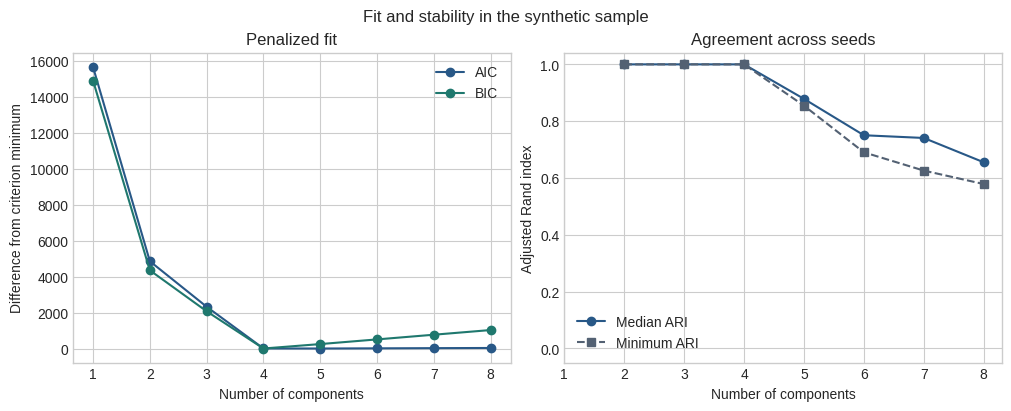

In [5]:
fig = plot_selection(metrics)
fig.savefig(figure_dir / "fit-and-stability.png", dpi=170, bbox_inches="tight")
plt.show()

## 8. General elevation versus profile shape

Each centroid is a vector of 25 fitted means. Its average is its **general elevation**. Subtracting that average from all 25 means leaves its **shape**, the relative emphasis across facets. The heatmaps share a scale within each column. Profiles are ordered by elevation separately for each model.

The elevation share below is the fraction of weighted between-centroid variation along the direction that changes all 25 facets equally. The remaining fraction describes shape. It is a descriptive partition of centroid variation in this sample.

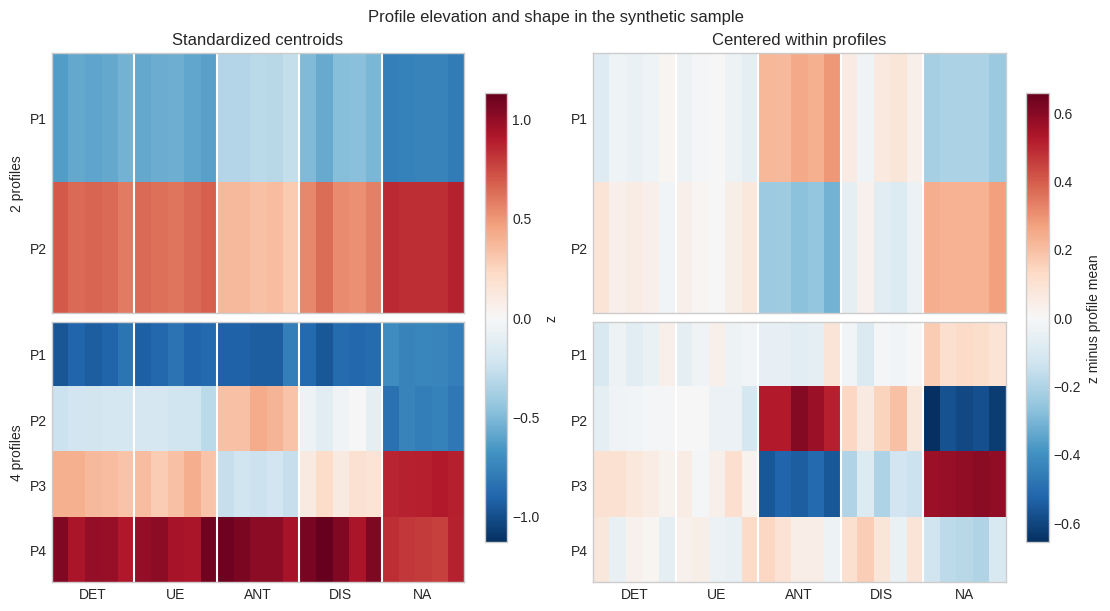

In [6]:
profiles = {k: summaries[k][1:3] for k in (2, 4)}
fig = plot_profiles(profiles, BLOCKS)
fig.savefig(figure_dir / "profile-elevation-and-shape.png", dpi=170, bbox_inches="tight")
plt.show()

## 9. Two-profile solution

Two components summarize a broad lower-to-higher elevation gradient. The centered map still shows some relative contrasts. The table reports estimated mixture weights, modal counts and the mean and 10th percentile of posterior probabilities among the records assigned to each profile.

In [7]:
display(summaries[2][0].round(3))
print(f"Elevation share: {summaries[2][3]:.1%} · Minimum seed-pair ARI: {metrics.loc[2, 'min_ARI']:.3f}")

,n_modal,modal_pct,weight_pct,posterior_mean,posterior_p10,elevation_z
P1,524,52.4,52.399,1.0,1.0,-0.551
P2,476,47.6,47.601,1.0,1.0,0.607


Elevation share: 93.1% · Minimum seed-pair ARI: 1.000


## 10. Four-profile solution

Four components retain the broad low and high profiles and distinguish two intermediate profiles. One of the intermediate profiles has relatively higher antagonism and lower negative affect. The other shows the reverse. This contrast is easiest to see after centering. Modal proportions and estimated weights are displayed side by side.

,n_modal,modal_pct,weight_pct,posterior_mean,posterior_p10,elevation_z
P1,280,28.0,27.984,0.997,1.0,-0.866
P2,245,24.5,24.553,0.998,1.0,-0.189
P3,257,25.7,25.623,0.994,1.0,0.299
P4,218,21.8,21.840,0.997,1.0,0.971


Elevation share: 86.2% · Minimum seed-pair ARI: 1.000


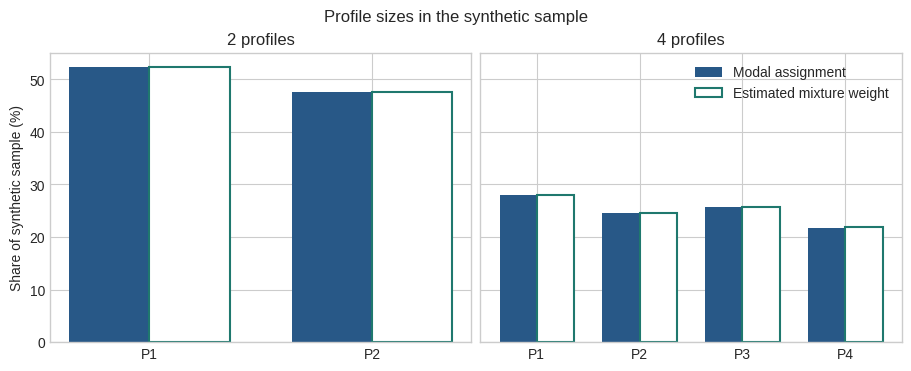

In [8]:
display(summaries[4][0].round(3))
print(f"Elevation share: {summaries[4][3]:.1%} · Minimum seed-pair ARI: {metrics.loc[4, 'min_ARI']:.3f}")

fig = plot_sizes({k: summaries[k][0] for k in (2, 4)})
fig.savefig(figure_dir / "profile-sizes.png", dpi=170, bbox_inches="tight")
plt.show()

## 11. Why more profiles are not always better

The six-component fit increases in-sample log-likelihood relative to four. Its penalized criteria are higher, its smallest group is smaller, and its assignments vary more across seeds. AIC reaches its overall minimum at five, while BIC reaches its minimum at four in this fixed simulation. The example illustrates why raw fit, a penalized criterion and assignment stability answer different questions.

In [9]:
display(metrics.loc[[2, 4, 6], ["log_likelihood", "AIC", "BIC", "relative_entropy",
                                 "min_modal_n", "converged_seeds", "median_ARI", "min_ARI"]].round(3))

,log_likelihood,AIC,BIC,relative_entropy,min_modal_n,converged_seeds,median_ARI,min_ARI
k,,,,,,,,
2,-30018.099,60238.198,60733.882,0.999,476,5,1.00,1.00
4,-27489.369,55384.738,56381.012,0.993,218,5,1.00,1.00
6,-27390.531,55391.063,56887.928,0.947,27,5,0.75,0.69


## 12. Limitations

The generator builds in four components, independent Gaussian noise within components and a clear contrast between two trait blocks. The results depend on that specification and the fixed seed. Seed agreement tests optimization on one dataset. Stability across samples and predictive performance would require additional validation. Psychological interpretation of real data would also require evidence about measurement, sampling and the assumptions of the mixture. These fictional profiles have no diagnostic meaning.

## 13. Takeaways

Two profiles are a concise description of broad elevation. Four reveal the designed contrast in relative shape and are stable across the tested seeds. Six improve raw in-sample fit and produce less stable assignments. A defensible interpretation considers fit, parsimony, group sizes, posterior certainty and stability alongside the shape of the profiles.